# Online Retail: Data Quality, Cleaning and Sales Analysis

## Project objective
Use Python to inspect transaction data, document cleaning decisions,
visualise sales patterns, and investigate how data quality affects findings.

## Questions
- What data quality issues are present?
- How does monthly gross merchandise sales value change?
- Which products lead, and how sensitive are their rankings to unusual entries?
- How is sales value distributed across countries and identified customers?

## Dataset
UCI Online Retail: transactions from a UK-based online retailer.

Source: https://archive.ics.uci.edu/dataset/352/online+retail

Each row represents an invoice line, rather than a complete order.

## Tools
Python, pandas, Matplotlib, and Google Colab.

## Analysis scope
Monthly analysis covers December 2010–November 2011.
The partial month of December 2011 is excluded.

The original gross-sales view excludes cancellations, non-positive
quantities and prices, identified non-merchandise codes, and exact repeats.

A separate sensitivity view additionally excludes two investigated
positive entries with evidence of subsequent offsets. Country and
customer analyses use this sensitivity view.

These measures are not net revenue or profit.

## 2. Load and understand the data

Download the dataset and inspect its rows, columns, and data types.

In [1]:
import pandas as pd

# Download the public dataset and load it into a table.
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

retail_data = pd.read_excel(
    __import__("io").BytesIO(
        __import__("zipfile").ZipFile(
            __import__("io").BytesIO(
                __import__("requests").get(url).content
            )
        ).read("Online Retail.xlsx")
    )
)

# Display the first five rows.
retail_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Show the number of rows and columns.
retail_data.shape

(541909, 8)

In [3]:
# inspect the data before making changes
# Show column names, non-missing counts, and data types.
retail_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 3. Data quality checks

Check for missing values, exact duplicate rows, unusual quantities,
zero or negative prices, and cancellation entries.

Investigate flagged records before deciding how to handle them.

In [4]:
# Count missing values in each column.
retail_data.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [5]:
#checking for duplicates
# count rows that exactly repeat an earlier row across all columns
retail_data.duplicated().sum()
# display examples of repeated rows
retail_data[retail_data.duplicated()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [6]:
import pandas as pd

# Download the public dataset and load it into a table.
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

retail_data = pd.read_excel(
    __import__("io").BytesIO(
        __import__("zipfile").ZipFile(
            __import__("io").BytesIO(
                __import__("requests").get(url).content
            )
        ).read("Online Retail.xlsx")
    )
)

# Display the first five rows.
retail_data.head()

# Show the number of rows and columns.
retail_data.shape
# Show column names, non-missing counts, and data types.
retail_data.info()
# Count missing values in each column.
retail_data.isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [7]:
# Count rows that exactly repeat an earlier row across all columns.
retail_data.duplicated().sum()
# Display examples of repeated rows.
retail_data[retail_data.duplicated()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


In [8]:
#count repeated rows, excluding the first occurrence
duplicate_count = retail_data.duplicated().sum()
print("Exat duplicate Rows:", duplicate_count)

Exat duplicate Rows: 5268


In [9]:
# select every row that exactly matches the row labelled 517
example_row = retail_data.loc[517]
matching_rows = retail_data[retail_data.eq(example_row).all(axis=1)]
matching_rows

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom


Duplicate check: Exact repeated rows were detected across all eight columns.
Their cause has not yet been confirmed, so no rows have been removed.

In [10]:
# Checking quantities and prices.
#summarise the numeric values in these two columns
retail_data[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [11]:
# Count rows meeting each condition.
# let’s count how often quantities and prices are zero or negative.
print("Negative quantities:", (retail_data["Quantity"] < 0).sum())
print("Zero quantities:", (retail_data["Quantity"] == 0).sum())

print("Negative prices:", (retail_data["UnitPrice"] < 0).sum())
print("Zero prices:", (retail_data["UnitPrice"] == 0).sum())

Negative quantities: 10624
Zero quantities: 0
Negative prices: 2
Zero prices: 2515


In [12]:
# Display every row with a negative unit price.
retail_data[retail_data["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [13]:
# Display the first five rows with a negative quantity.
retail_data[retail_data["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [14]:
# Identify invoices whose numbers start with C.
is_cancellation = (
    retail_data["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

print("Cancellation rows:", is_cancellation.sum())

# Count negative quantities on invoices that do not start with C.
negative_without_c = (
    (retail_data["Quantity"] < 0) & (~is_cancellation)
)

print("Negative quantities without C:", negative_without_c.sum())

Cancellation rows: 9288
Negative quantities without C: 1336


In [15]:
# inspect examples of negative quantities without a cancellation prefix:
retail_data[negative_without_c].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [16]:
# inspect zero-price entries:
retail_data[retail_data["UnitPrice"] == 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


Quantity and price checks:
Found 10,624 negative-quantity rows, no zero quantities,
two negative-price rows, and 2,515 zero-price rows.
Both negative-price rows are labelled “Adjust bad debt.” Cancellation and adjustment entries require separate treatment when defining sales metrics.

first analysis table. Initial question:
What patterns appear in positive-value sales entries before subtracting cancellations?

## 4. Cleaning decisions and validation

Create separate analysis tables while preserving the original dataset.

Select positive-quantity, positive-price entries without cancellation
prefixes. Exclude identified non-merchandise codes and remove exact
repeated rows as a documented assumption.

Retain missing customer IDs for sales analysis, but exclude them from
individual-customer analysis.

Validate the resulting tables and check the transaction date range.

In [17]:
# Define which rows belong in our initial sales analysis.
sales_mask = (
    (retail_data["Quantity"] > 0)
    & (retail_data["UnitPrice"] > 0)
    & (~is_cancellation)
)

# Create a separate table, keeping the original data unchanged.
sales_data = retail_data.loc[sales_mask].copy()

print("Original rows:", len(retail_data))
print("Rows included:", len(sales_data))
print("Rows excluded:", len(retail_data) - len(sales_data))

Original rows: 541909
Rows included: 530104
Rows excluded: 11805


In [18]:
# Quantity multiplied by price gives the value of each invoice line.
sales_data["LineValue"] = (
    sales_data["Quantity"] * sales_data["UnitPrice"]
)

sales_data[
    ["InvoiceNo", "Quantity", "UnitPrice", "LineValue"]
].head()

,InvoiceNo,Quantity,UnitPrice,LineValue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [19]:
# validate the selection:
print(
    "Non-positive quantities remaining:",
    (sales_data["Quantity"] <= 0).sum()
)

print(
    "Non-positive prices remaining:",
    (sales_data["UnitPrice"] <= 0).sum()
)

print(
    "Cancellation rows remaining:",
    sales_data["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
    .sum()
)

Non-positive quantities remaining: 0
Non-positive prices remaining: 0
Cancellation rows remaining: 0


In [20]:
# Count missing values in our selected sales rows.
sales_data.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,132220
Country,0
LineValue,0


In [21]:
# Inspect product codes containing no digits
# Convert product codes to text for inspection.
stock_codes = sales_data["StockCode"].astype("string")

# Identify codes that contain no digits.
no_digits = ~stock_codes.str.contains(r"\d", na=False)

# Show each distinct code and description found.
sales_data.loc[
    no_digits,
    ["StockCode", "Description"]
].drop_duplicates().sort_values("StockCode")

,StockCode,Description
15017,AMAZONFEE,AMAZON FEE
299982,B,Adjust bad debt
4406,BANK CHARGES,Bank Charges
84016,DCGSSBOY,BOYS PARTY BAG
84017,DCGSSGIRL,GIRLS PARTY BAG
1814,DOT,DOTCOM POSTAGE
2239,M,Manual
157195,PADS,PADS TO MATCH ALL CUSHIONS
45,POST,POSTAGE
152709,S,SAMPLES


In [22]:
# now create a merchandise analysis table using an explicit, documented exclusion list.
# Exclude manual entries and samples because their descriptions don’t clearly identify ordinary merchandise sales.
# That is an analysis choice, not proof that those records are incorrect.

In [23]:
# Standardise codes for comparison: remove surrounding spaces
# and convert letters to uppercase.
normalised_codes = (
    sales_data["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Codes we will exclude from merchandise analysis.
excluded_codes = [
    "AMAZONFEE",
    "B",
    "BANK CHARGES",
    "DOT",
    "M",
    "POST",
    "S"
]

# Identify rows whose codes appear in our exclusion list.
exclude_from_merchandise = normalised_codes.isin(excluded_codes)

# Create a separate merchandise table.
merchandise_data = sales_data.loc[
    ~exclude_from_merchandise
].copy()

print("Sales rows:", len(sales_data))
print("Rows excluded by code:", exclude_from_merchandise.sum())
print("Merchandise rows:", len(merchandise_data))

Sales rows: 530104
Rows excluded by code: 2171
Merchandise rows: 527933


In [24]:
print(
    "Exact duplicate merchandise rows:",
    merchandise_data.duplicated().sum()
)

Exact duplicate merchandise rows: 5221


Merchandise scope: Selected positive-quantity, positive-price entries without cancellation prefixes. Excluded identified postage, fee, accounting, manual, and sample codes. Retained letter-only codes describing products and rows with missing customer IDs. This classification is based on the inspected descriptions and may not identify every non-merchandise entry.

In [25]:
# Mark repeated rows, keeping the first occurrence unmarked.
duplicate_rows = merchandise_data.duplicated()

# Calculate sales value with all rows retained.
value_with_duplicates = merchandise_data["LineValue"].sum()

# Calculate the value contributed by repeated rows.
duplicate_value = merchandise_data.loc[
    duplicate_rows, "LineValue"
].sum()

# Calculate sales value if repeated rows were removed.
value_without_duplicates = value_with_duplicates - duplicate_value

print(f"Value with repeats retained: £{value_with_duplicates:,.2f}")
print(f"Value in repeated rows: £{duplicate_value:,.2f}")
print(f"Value with repeats removed: £{value_without_duplicates:,.2f}")

print(
    f"Percentage of value in repeated rows: "
    f"{duplicate_value / value_with_duplicates * 100:.2f}%"
)

Value with repeats retained: £10,279,169.87
Value in repeated rows: £24,213.74
Value with repeats removed: £10,254,956.13
Percentage of value in repeated rows: 0.24%


In [26]:
# remove exact repeats as a documented assumption, while preserving the original tables
# Remove exact repeated rows, keeping the first occurrence.
clean_merchandise = merchandise_data.drop_duplicates().copy()

print("Rows before:", len(merchandise_data))
print("Rows after:", len(clean_merchandise))
print("Rows removed:", len(merchandise_data) - len(clean_merchandise))

Rows before: 527933
Rows after: 522712
Rows removed: 5221


In [27]:
# Validate the result
print(
    "Exact duplicates remaining:",
    clean_merchandise.duplicated().sum()
)

print(
    "Non-positive quantities:",
    (clean_merchandise["Quantity"] <= 0).sum()
)

print(
    "Non-positive prices:",
    (clean_merchandise["UnitPrice"] <= 0).sum()
)

print(
    f"Gross merchandise sales value: "
    f"£{clean_merchandise['LineValue'].sum():,.2f}"
)

Exact duplicates remaining: 0
Non-positive quantities: 0
Non-positive prices: 0
Gross merchandise sales value: £10,254,956.13


Duplicate treatment: Removed 5,221 exact repeated merchandise rows, retaining the first occurrence. Without a unique invoice-line identifier, these repeats cannot be confirmed as errors. Removing them reduced gross merchandise sales value by £24,213.74 (0.24%). Original data was preserved. This measure excludes cancellations and identified non-merchandise codes; it is not net revenue.

In [28]:
# check the date coverage before plotting sales over time
print("Earliest transaction:", clean_merchandise["InvoiceDate"].min())
print("Latest transaction:", clean_merchandise["InvoiceDate"].max())

Earliest transaction: 2010-12-01 08:26:00
Latest transaction: 2011-12-09 12:50:00


## 5. Monthly sales analysis

Calculate and visualise monthly gross merchandise sales value
from December 2010 to November 2011.

Exclude December 2011 because records end on 9 December.
Compare monthly totals and percentage changes.

This analysis uses the original gross-sales view, before the later
sensitivity exclusions. It does not measure net revenue or profit.

In [29]:
# Select records before the partial month of December 2011.
monthly_chart_data = clean_merchandise[
    clean_merchandise["InvoiceDate"] < "2011-12-01"
].copy()

# Group invoice lines by calendar month and add their values.
monthly_sales = (
    monthly_chart_data
    .groupby(monthly_chart_data["InvoiceDate"].dt.to_period("M"))
    ["LineValue"]
    .sum()
)

monthly_sales

,LineValue
InvoiceDate,
2010-12,776314.950
2011-01,670639.460
2011-02,508081.540
2011-03,690591.840
2011-04,515869.661
2011-05,740472.330
2011-06,738233.990
2011-07,688802.671
2011-08,724708.160


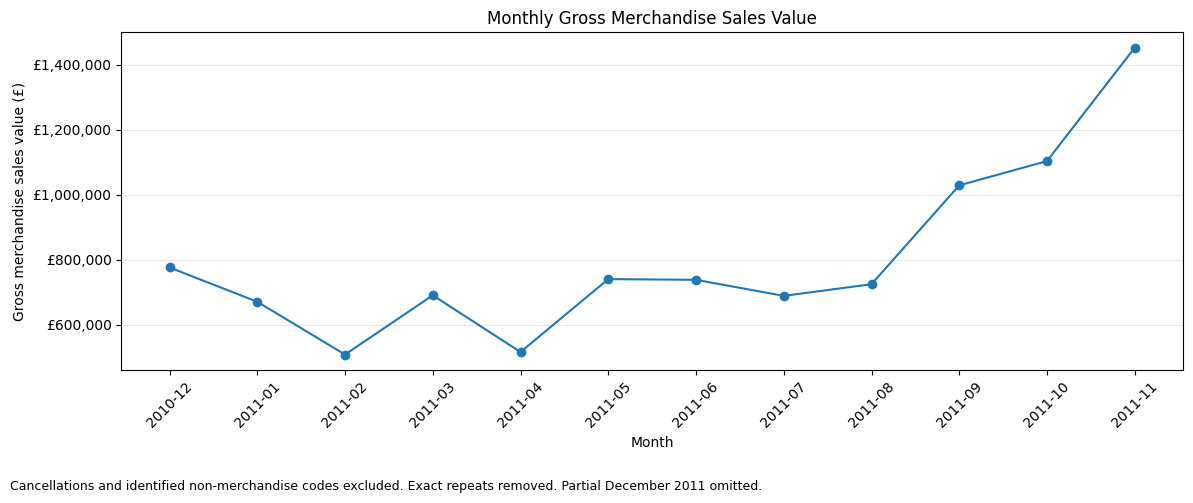

In [30]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Create the chart area.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

ax.set_title("Monthly Gross Merchandise Sales Value")
ax.set_xlabel("Month")
ax.set_ylabel("Gross merchandise sales value (£)")

# Display pound amounts with commas and no decimal places.
ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

fig.text(
    0.01, 0.01,
    "Cancellations and identified non-merchandise codes excluded. "
    "Exact repeats removed. Partial December 2011 omitted.",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

Monthly gross merchandise sales value fluctuated between January and August 2011, before increasing each month from September through November. November recorded the highest value (£1,453,265.98), while February recorded the lowest (£508,081.54). December 2011 was excluded because records end on 9 December. These totals exclude cancellations and identified non-merchandise entries, with exact duplicates removed.

In [31]:
# Calculate the percentage change from each month to the next.
monthly_change = monthly_sales.pct_change() * 100

# Combine the totals and percentage changes into one table.
monthly_summary = pd.DataFrame({
    "GrossSalesValue": monthly_sales,
    "ChangePercent": monthly_change
})

monthly_summary.round(2)

,GrossSalesValue,ChangePercent
InvoiceDate,,
2010-12,776314.95,NaN
2011-01,670639.46,-13.61
2011-02,508081.54,-24.24
2011-03,690591.84,35.92
2011-04,515869.66,-25.30
2011-05,740472.33,43.54
2011-06,738233.99,-0.30
2011-07,688802.67,-6.70
2011-08,724708.16,5.21


May recorded the largest monthly percentage increase (43.54%), followed by September (42.02%). April recorded the largest percentage decline (25.30%). These comparisons use monthly totals without adjusting for differences in month length.

## 6. Product analysis and transaction investigation

Rank products by gross merchandise sales value and investigate
whether unusually large invoice lines influence the rankings.

Inspect original records for possible cancellations and corrections,
including adjustments recorded under different product codes.

Compare the original gross-sales view with a sensitivity view that
excludes two investigated positive entries with evidence of offsets.

The sensitivity view is not a net-sales calculation.

In [32]:
# Group by product code and add each product's line values.
product_sales = (
    monthly_chart_data
    .groupby("StockCode")["LineValue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 10 products with the highest values.
top_10_products = product_sales.head(10)

top_10_products.round(2)

,LineValue
StockCode,
22423,168162.42
85123A,102236.34
47566,98526.75
85099B,91932.91
23166,81448.21
22086,58007.83
23084,57241.57
84879,56764.88
79321,51456.62


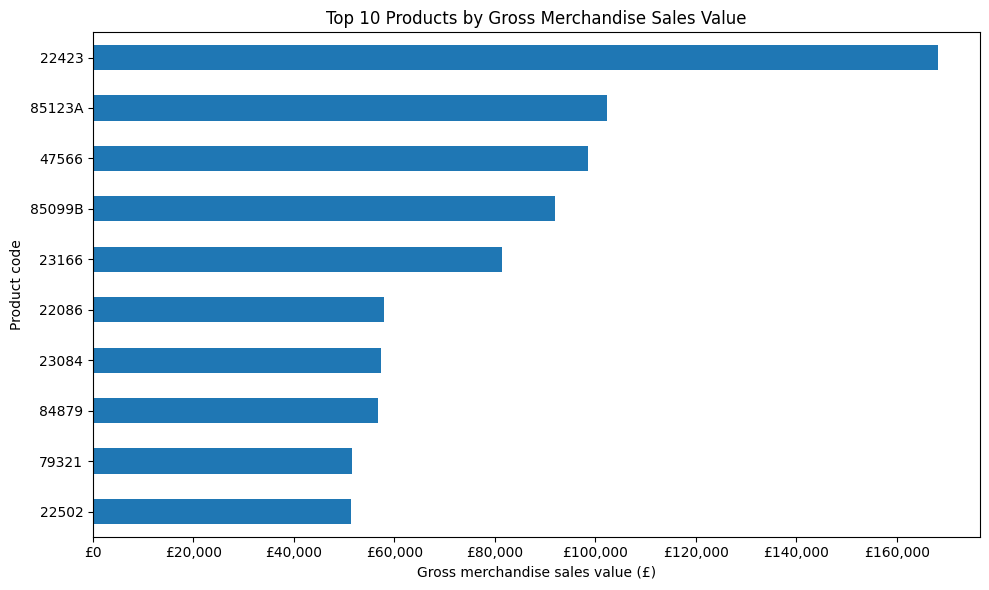

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))

# Sort for display so the largest bar appears at the top.
top_10_products.sort_values().plot.barh(ax=ax)

ax.set_title("Top 10 Products by Gross Merchandise Sales Value")
ax.set_xlabel("Gross merchandise sales value (£)")
ax.set_ylabel("Product code")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))

plt.tight_layout()
plt.show()

In [34]:
# Select the rows belonging to our top 10 products.
top_product_rows = monthly_chart_data[
    monthly_chart_data["StockCode"].isin(top_10_products.index)
]

# Summarise each product.
product_summary = (
    top_product_rows
    .groupby("StockCode")
    .agg(
        Description=("Description", lambda values: values.mode().iloc[0]),
        GrossSalesValue=("LineValue", "sum"),
        Units=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        LargestLineValue=("LineValue", "max")
    )
)

# Calculate how much each product's largest line contributes.
product_summary["LargestLinePercent"] = (
    product_summary["LargestLineValue"]
    / product_summary["GrossSalesValue"]
    * 100
)

product_summary.sort_values(
    "GrossSalesValue", ascending=False
).round(2)

,Description,GrossSalesValue,Units,InvoiceCount,LargestLineValue,LargestLinePercent
StockCode,,,,,,
22423,REGENCY CAKESTAND 3 TIER,168162.42,13402,1929,2978.40,1.77
85123A,WHITE HANGING HEART T-LIGHT HOLDER,102236.34,36826,2132,4921.50,4.81
47566,PARTY BUNTING,98526.75,18147,1657,1542.97,1.57
85099B,JUMBO BAG RED RETROSPOT,91932.91,47266,2036,1980.00,2.15
23166,MEDIUM CERAMIC TOP STORAGE JAR,81448.21,77826,233,77183.60,94.76
22086,PAPER CHAIN KIT 50'S CHRISTMAS,58007.83,17241,1044,4781.60,8.24
23084,RABBIT NIGHT LIGHT,57241.57,26435,867,4992.00,8.72
84879,ASSORTED COLOUR BIRD ORNAMENT,56764.88,35032,1408,4176.00,7.36
79321,CHILLI LIGHTS,51456.62,9840,630,2232.00,4.34


In [35]:
flagged_codes = ["23166", "22502"]

# Convert codes to text so comparisons work consistently.
product_codes = monthly_chart_data["StockCode"].astype("string")

largest_lines = (
    monthly_chart_data[
        product_codes.isin(flagged_codes)
    ]
    .sort_values("LineValue", ascending=False)
    .drop_duplicates(subset="StockCode")
)

largest_lines[
    [
        "InvoiceNo", "StockCode", "Description", "Quantity",
        "InvoiceDate", "UnitPrice", "CustomerID", "LineValue"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,LineValue
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,77183.6
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.0,38970.0


In [36]:
original_codes = retail_data["StockCode"].astype("string")

possible_reversals = retail_data[
    original_codes.isin(flagged_codes)
    & (retail_data["Quantity"] < 0)
].copy()

# Calculate signed values: negative quantities produce negative amounts.
possible_reversals["LineValue"] = (
    possible_reversals["Quantity"]
    * possible_reversals["UnitPrice"]
)

possible_reversals.sort_values("LineValue").head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,-77183.60
222692,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95,15098.0,United Kingdom,-297.00
234364,C557508,23166,MEDIUM CERAMIC TOP STORAGE JAR,-240,2011-06-20 16:13:00,1.04,16684.0,United Kingdom,-249.60
146119,C548972,22502,PICNIC BASKET WICKER SMALL,-4,2011-04-05 11:42:00,5.95,15674.0,United Kingdom,-23.80
225288,C556647,22502,PICNIC BASKET WICKER SMALL,-4,2011-06-13 16:14:00,5.95,13012.0,United Kingdom,-23.80
290357,C562375,23166,MEDIUM CERAMIC TOP STORAGE JAR,-12,2011-08-04 14:46:00,1.25,14911.0,EIRE,-15.00
394002,C570867,23166,MEDIUM CERAMIC TOP STORAGE JAR,-12,2011-10-12 16:17:00,1.25,12607.0,USA,-15.00
140805,C548467,22502,PICNIC BASKET WICKER SMALL,-2,2011-03-31 12:20:00,5.95,16619.0,United Kingdom,-11.90
203625,C554527,23166,MEDIUM CERAMIC TOP STORAGE JAR,-9,2011-05-24 17:25:00,1.04,15251.0,United Kingdom,-9.36
119147,C546529,22502,PICNIC BASKET WICKER SMALL,-1,2011-03-14 13:05:00,5.95,15502.0,United Kingdom,-5.95


Transaction investigation: A £77,183.60 positive entry for product 23166 has an equal opposite entry for the same customer and product 16 minutes later, strongly supporting a full reversal. A £38,970 entry for product 22502 remains unresolved: a nearby cancellation uses a different unit price and offsets only £297. No additional records were removed during this investigation.

In [37]:
# Select records for customer 15098 on 10 June 2011.
customer_day = retail_data[
    (retail_data["CustomerID"] == 15098)
    & (retail_data["InvoiceDate"] >= "2011-06-10")
    & (retail_data["InvoiceDate"] < "2011-06-11")
].copy()

# Calculate each line's signed value.
customer_day["LineValue"] = (
    customer_day["Quantity"] * customer_day["UnitPrice"]
)

customer_day.sort_values("InvoiceDate")[
    [
        "InvoiceNo", "StockCode", "Description",
        "Quantity", "InvoiceDate", "UnitPrice", "LineValue"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,LineValue
222670,556442,22502,PICNIC BASKET WICKER SMALL,60,2011-06-10 15:22:00,4.95,297.0
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,38970.0
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,-38970.0
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50,649.5
222692,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95,-297.0


Correction-chain investigation: Five entries for customer 15098 on 10 June 2011 sum to £649.50. A £38,970 positive product entry is followed three minutes later by an equal manual cancellation, strongly suggesting a correction. Excluding manual entries and cancellations from the gross-sales view conceals this offset. Gross-sales rankings should therefore not be interpreted as net sales performance.

In [38]:
print(
    f"Combined value of the displayed customer-day entries: "
    f"£{customer_day['LineValue'].sum():,.2f}"
)

Combined value of the displayed customer-day entries: £649.50


In [39]:
# Row labels of the two investigated large positive entries.
flagged_row_labels = [61619, 222680]

# Create an alternative view without those entries.
sensitivity_data = monthly_chart_data.drop(
    index=flagged_row_labels
)

# Recalculate product totals under this alternative assumption.
sensitivity_top_10 = (
    sensitivity_data
    .groupby("StockCode")["LineValue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

sensitivity_top_10.round(2)

,LineValue
StockCode,
22423,168162.42
85123A,102236.34
47566,98526.75
85099B,91932.91
22086,58007.83
23084,57241.57
84879,56764.88
79321,51456.62
22197,45910.67


The top four products were unchanged in the sensitivity comparison. However, the original fifth-ranked product, 23166, and tenth-ranked product, 22502, depended heavily on large transactions with evidence of subsequent offsets. Their original rankings should not be interpreted as sustained sales performance.

In [40]:
# Calculate alternative totals for every product.
sensitivity_product_sales = (
    sensitivity_data
    .groupby("StockCode")["LineValue"]
    .sum()
)

# Standardise the indexes to string to prevent mixed-type comparison errors during alignment.
product_sales.index = product_sales.index.astype(str)
sensitivity_product_sales.index = sensitivity_product_sales.index.astype(str)

# Compare the two investigated products.
comparison = pd.DataFrame({
    "Original gross view": product_sales,
    "Sensitivity view": sensitivity_product_sales
}).loc[["23166", "22502"]]

comparison.round(2)

,Original gross view,Sensitivity view
StockCode,,
23166,81448.21,4264.61
22502,51408.77,12438.77


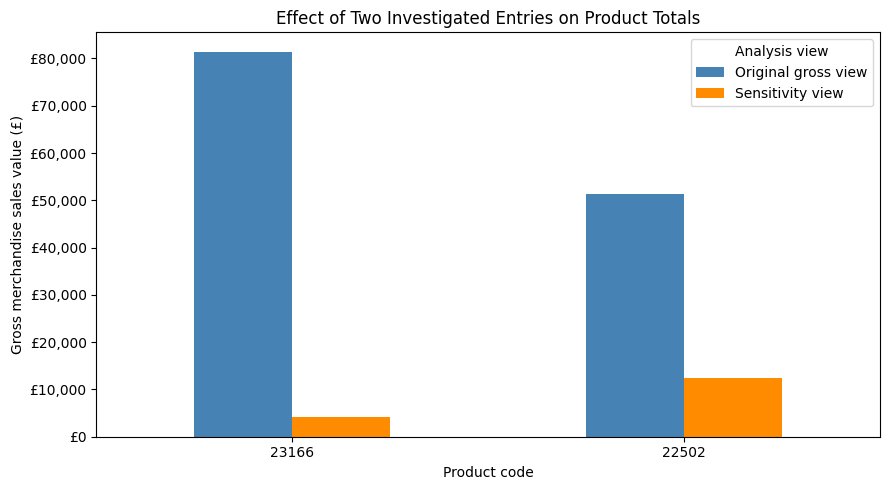

In [41]:
ax = comparison.plot.bar(
    figsize=(9, 5),
    rot=0,
    color=["steelblue", "darkorange"]
)

ax.set_title("Effect of Two Investigated Entries on Product Totals")
ax.set_xlabel("Product code")
ax.set_ylabel("Gross merchandise sales value (£)")
ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.legend(title="Analysis view")

plt.tight_layout()
plt.show()

Excluding two large positive entries with evidence of subsequent offsets substantially reduced the gross sales totals for products 23166 and 22502. Both dropped out of the top 10, while the four leading products remained unchanged. This demonstrates how individual transactions can influence product rankings. The sensitivity view does not represent net sales.

## 7. Country analysis

Compare gross merchandise sales value across countries and calculate
each country's share of the total.

Create a separate chart excluding the UK to make differences between
the other markets easier to see.

This analysis uses the sensitivity view for December 2010–November 2011.
It does not measure market size, net revenue, or profitability.

In [42]:
# Add line values for each country and sort from highest to lowest.
country_sales = (
    sensitivity_data
    .groupby("Country")["LineValue"]
    .sum()
    .sort_values(ascending=False)
)

# Calculate each country's percentage of the total.
country_summary = pd.DataFrame({
    "GrossSalesValue": country_sales,
    "SharePercent": country_sales / country_sales.sum() * 100
})

country_summary.head(10).round(2)

,GrossSalesValue,SharePercent
Country,,
United Kingdom,8039162.22,84.41
Netherlands,272161.32,2.86
EIRE,268749.97,2.82
Germany,198356.98,2.08
France,178140.08,1.87
Australia,138103.81,1.45
Spain,55418.35,0.58
Switzerland,53065.60,0.56
Japan,37416.37,0.39


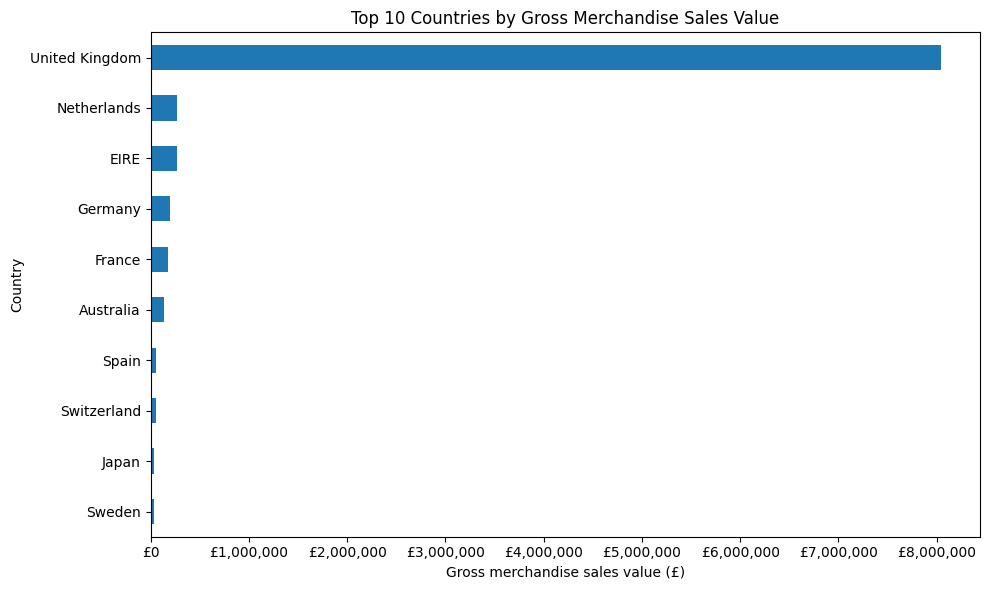

In [43]:
ax = (
    country_sales.head(10)
    .sort_values()
    .plot.barh(figsize=(10, 6))
)

ax.set_title("Top 10 Countries by Gross Merchandise Sales Value")
ax.set_xlabel("Gross merchandise sales value (£)")
ax.set_ylabel("Country")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))

plt.tight_layout()
plt.show()

Sales value was concentrated in the United Kingdom, which contributed 84.41% of the total. The Netherlands and Ireland were the largest markets outside the UK. These results describe this retailer’s recorded sales under our analysis rules; they do not measure market size or profitability.

In [44]:
# Define country_sales using the sensitivity_data
country_sales = (
    sensitivity_data
    .groupby("Country")["LineValue"]
    .sum()
    .sort_values(ascending=False)
)

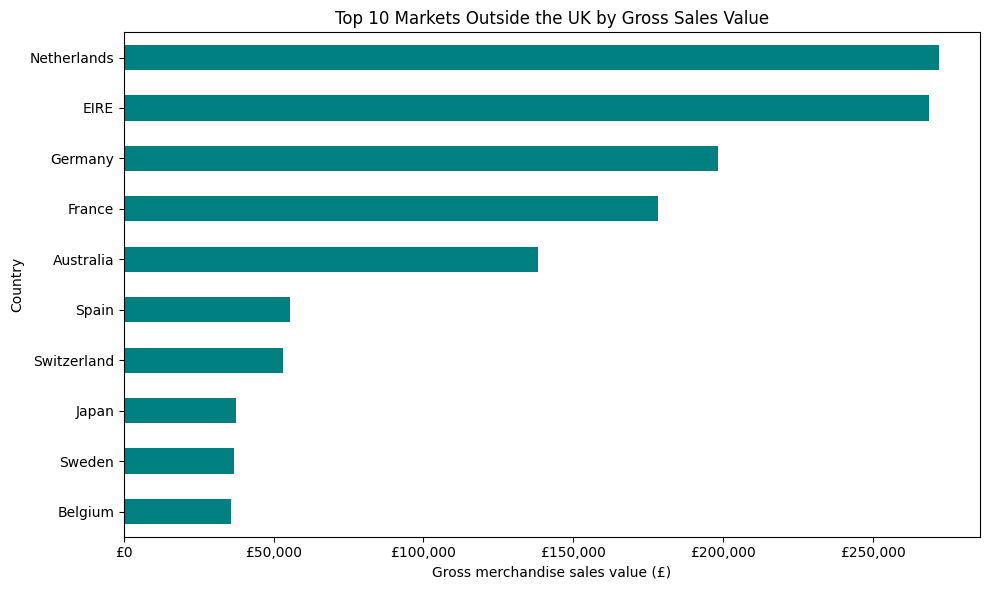

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# 1. Download and load the raw dataset
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
retail_data = pd.read_excel(
    __import__("io").BytesIO(
        __import__("zipfile").ZipFile(
            __import__("io").BytesIO(
                __import__("requests").get(url).content
            )
        ).read("Online Retail.xlsx")
    )
)

# 2. Filter cancellation rows and build positive sales dataset
is_cancellation = retail_data["InvoiceNo"].astype(str).str.upper().str.startswith("C", na=False)
sales_mask = (retail_data["Quantity"] > 0) & (retail_data["UnitPrice"] > 0) & (~is_cancellation)
sales_data = retail_data.loc[sales_mask].copy()
sales_data["LineValue"] = sales_data["Quantity"] * sales_data["UnitPrice"]

# 3. Standardize product codes, apply merchandise exclusions and drop duplicate rows
normalised_codes = sales_data["StockCode"].astype(str).str.strip().str.upper()
excluded_codes = ["AMAZONFEE", "B", "BANK CHARGES", "DOT", "M", "POST", "S"]
exclude_from_merchandise = normalised_codes.isin(excluded_codes)
merchandise_data = sales_data.loc[~exclude_from_merchandise].copy()
clean_merchandise = merchandise_data.drop_duplicates().copy()

# 4. Filter data to include only records prior to Dec 2011 and apply sensitivity drops
monthly_chart_data = clean_merchandise[clean_merchandise["InvoiceDate"] < "2011-12-01"].copy()
flagged_row_labels = [61619, 222680]
sensitivity_data = monthly_chart_data.drop(index=flagged_row_labels, errors='ignore')

# 5. Aggregate sales to define country_sales
country_sales = (
    sensitivity_data
    .groupby("Country")["LineValue"]
    .sum()
    .sort_values(ascending=False)
)

# 6. Plot the top 10 international markets
international_sales = (
    country_sales
    .drop(index="United Kingdom", errors='ignore')
    .head(10)
)

fig, ax = plt.subplots(figsize=(10, 6))
international_sales.sort_values().plot.barh(ax=ax, color="teal")

ax.set_title("Top 10 Markets Outside the UK by Gross Sales Value")
ax.set_xlabel("Gross merchandise sales value (£)")
ax.set_ylabel("Country")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))

plt.tight_layout()
plt.show()

In [46]:
international_sales.round(2)

,LineValue
Country,
Netherlands,272161.32
EIRE,268749.97
Germany,198356.98
France,178140.08
Australia,138103.81
Spain,55418.35
Switzerland,53065.60
Japan,37416.37
Sweden,36590.83


## 8. Customer analysis

Measure customer-ID coverage, then analyse identified customers'
invoice counts, gross sales values, and average invoice values.

Calculate the percentage of identified customers with at least two
included invoices and the top 10 customers' share of identified sales.

This analysis uses the sensitivity view for December 2010–November 2011.
Missing customer IDs are excluded from individual-customer calculations.

Multiple invoices do not establish customer retention, and gross sales
value does not measure profit.

In [47]:
# Identify rows with a recorded customer ID.
has_customer_id = sensitivity_data["CustomerID"].notna()

# Create a separate table for customer analysis.
customer_data = sensitivity_data.loc[has_customer_id].copy()

print("Rows with customer IDs:", len(customer_data))
print("Rows without customer IDs:", (~has_customer_id).sum())
print("Distinct recorded customers:", customer_data["CustomerID"].nunique())

# Calculate the percentage of sales value linked to a customer ID.
identified_value = customer_data["LineValue"].sum()
total_value = sensitivity_data["LineValue"].sum()

print(
    f"Sales value linked to customer IDs: "
    f"{identified_value / total_value * 100:.2f}%"
)

Rows with customer IDs: 374317
Rows without customer IDs: 123635
Distinct recorded customers: 4292
Sales value linked to customer IDs: 85.21%


In [48]:
# Summarise each identified customer's recorded purchases.
customer_summary = (
    customer_data
    .groupby("CustomerID")
    .agg(
        InvoiceCount=("InvoiceNo", "nunique"),
        GrossSalesValue=("LineValue", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
)

# Calculate average included value per distinct invoice.
customer_summary["AverageInvoiceValue"] = (
    customer_summary["GrossSalesValue"]
    / customer_summary["InvoiceCount"]
)

# Display the 10 customers with the highest gross sales value.
customer_summary.sort_values(
    "GrossSalesValue", ascending=False
).head(10).round(2)

,InvoiceCount,GrossSalesValue,FirstPurchase,LastPurchase,AverageInvoiceValue
CustomerID,,,,,
14646.0,69,267410.00,2010-12-20 10:09:00,2011-11-23 11:06:00,3875.51
18102.0,57,248171.76,2010-12-07 16:42:00,2011-11-28 12:55:00,4353.89
17450.0,45,192828.39,2010-12-07 09:23:00,2011-11-29 09:56:00,4285.08
14911.0,190,133357.91,2010-12-01 14:05:00,2011-11-30 15:08:00,701.88
12415.0,20,124564.53,2011-01-06 11:12:00,2011-11-15 14:22:00,6228.23
14156.0,55,117210.08,2010-12-03 11:48:00,2011-11-30 10:54:00,2131.09
17511.0,29,83683.06,2010-12-01 10:19:00,2011-11-23 10:31:00,2885.62
16029.0,62,72708.09,2010-12-01 09:57:00,2011-11-01 10:27:00,1172.71
13694.0,47,61908.46,2010-12-01 12:12:00,2011-11-14 11:11:00,1317.20


In [49]:
# Identify customers with two or more included invoices.
multiple_invoice_customers = customer_summary["InvoiceCount"] >= 2

print(
    "Customers with at least two invoices:",
    multiple_invoice_customers.sum()
)

print(
    f"Percentage with at least two invoices: "
    f"{multiple_invoice_customers.mean() * 100:.2f}%"
)

Customers with at least two invoices: 2742
Percentage with at least two invoices: 63.89%


In [50]:
# Sort customers by gross sales value.
ranked_customers = customer_summary.sort_values(
    "GrossSalesValue", ascending=False
)

# Calculate the top 10 customers' share.
top_10_value = ranked_customers.head(10)["GrossSalesValue"].sum()
identified_customer_value = customer_summary["GrossSalesValue"].sum()

top_10_share = top_10_value / identified_customer_value * 100

print(f"Top 10 customer gross sales value: £{top_10_value:,.2f}")
print(f"Share of identified-customer sales value: {top_10_share:.2f}%")

Top 10 customer gross sales value: £1,363,093.86
Share of identified-customer sales value: 16.80%


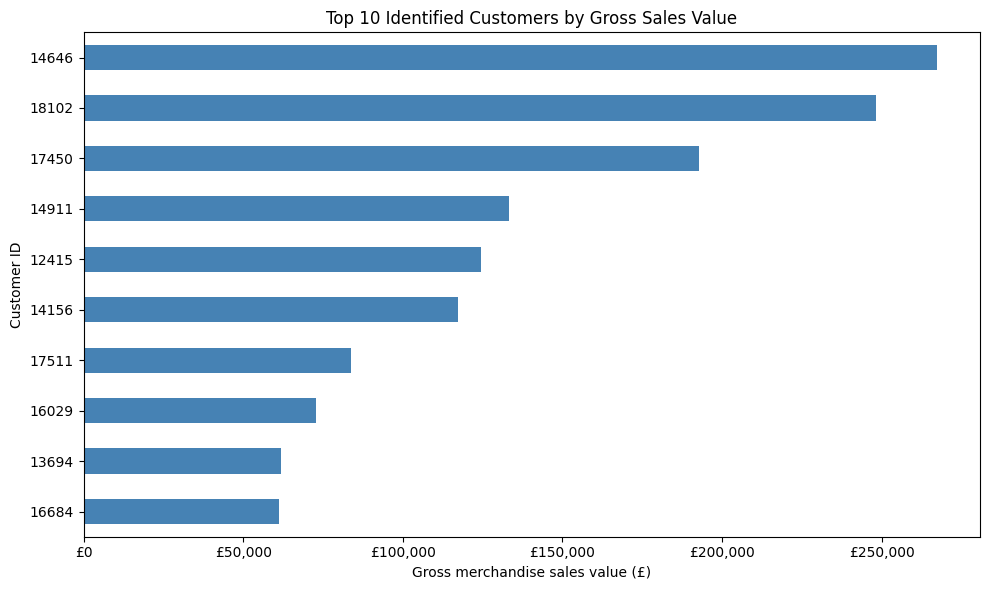

In [51]:
# Select and order the values for a horizontal bar chart.
top_customer_values = (
    ranked_customers.head(10)["GrossSalesValue"]
    .sort_values()
)

# Display customer IDs as labels without decimal places.
top_customer_values.index = (
    top_customer_values.index.astype("int64").astype(str)
)

ax = top_customer_values.plot.barh(
    figsize=(10, 6),
    color="steelblue"
)

ax.set_title("Top 10 Identified Customers by Gross Sales Value")
ax.set_xlabel("Gross merchandise sales value (£)")
ax.set_ylabel("Customer ID")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))

plt.tight_layout()
plt.show()

The top 10 identified customers contributed 16.80% of identified-customer gross merchandise sales value, indicating concentration among a small group of customers. Of 4,292 identified customers, 63.89% appeared on at least two included invoices. Customer IDs covered 85.21% of sales value, so these findings do not describe all purchasers. Results use the sensitivity view and do not represent net revenue or profit.

## 9. Conclusions and limitations

### Main findings

- In the original gross-sales view, November 2011 had the highest
  monthly value (£1,453,265.98). May had the largest month-to-month
  percentage increase (43.54%).

- Two large product entries had evidence of subsequent offsets.
  Excluding them in a sensitivity comparison changed the top 10
  product rankings, while the four leading products remained unchanged.

- In the sensitivity view, the UK contributed 84.41% of gross
  merchandise sales value. The Netherlands and Ireland were the
  largest markets outside the UK.

- Customer IDs covered 85.21% of sensitivity-view sales value.
  Among 4,292 identified customers, 63.89% had at least two included
  invoices. The top 10 contributed 16.80% of identified-customer
  sales value.

### Limitations

- Gross sales value is not net revenue or profit. Cancellations
  and adjustments were not comprehensively reconciled.

- Removing exact duplicates was a documented assumption:
  identical lines could represent legitimate purchases.

- The sensitivity comparison investigated two large entries;
  other unresolved transactions may remain.

- Missing customer IDs limit individual-customer analysis.

- December 2011 was excluded because records end on 9 December.
  The available period cannot establish recurring seasonal patterns.

- Monthly findings use the original gross-sales view. Country
  and customer findings use the sensitivity view.

### Skills practised

Python, pandas, data quality checks, documented cleaning decisions,
validation, Matplotlib visualisation, transaction investigation,
and interpretation of analytical findings.